## Imports

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
import pmdarima as pm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings("ignore")

HIST_COLOR       = "#2c3e50"
FC_COLOR         = "#2980b9"
CI_COLOR         = "#85c1e9"
TOTAL_COUNCILS   = 79
ALPHA            = 0.05
TARGET_YEAR      = 2030
DIVERSION_TARGET = 0.80

## Shared Functions
### Evaluation Functions

In [2]:
def mape(actual, predicted) -> float:
    actual, predicted = np.array(actual, dtype=float), np.array(predicted, dtype=float)
    mask = actual != 0
    return float(np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100)


def evaluate(actual, predicted, label: str, print_eval=True) -> dict:
    mae_v  = mean_absolute_error(actual, predicted)
    rmse_v = np.sqrt(mean_squared_error(actual, predicted))
    mape_v = mape(actual, predicted)
    if print_eval:
        print(f"    MAE  = {mae_v:.4f}")
        print(f"    RMSE = {rmse_v:.4f}")
        print(f"    MAPE = {mape_v:.2f}%")
    return {"series": label,
            "MAE":      round(mae_v,  4),
            "RMSE":     round(rmse_v, 4),
            "MAPE_pct": round(mape_v, 2)}


def ts_cross_validate(series: np.ndarray, order: tuple,
                      seasonal_order: tuple = (0, 0, 0, 0),
                      n_splits: int = 3, test_size: int = 1) -> dict:
    tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)
    maes, rmses, mapes = [], [], []
    for train_idx, test_idx in tscv.split(series):
        train, test = series[train_idx], series[test_idx]
        p = max(order[0], seasonal_order[0]) if seasonal_order else order[0]
        if len(train) < p + 5:
            continue
        try:
            fit  = SARIMAX(train, order=order, seasonal_order=seasonal_order,
                           enforce_stationarity=False, enforce_invertibility=False
                           ).fit(disp=False)
            pred = fit.forecast(steps=len(test))
            maes.append(mean_absolute_error(test, pred))
            rmses.append(np.sqrt(mean_squared_error(test, pred)))
            mapes.append(mape(test, pred))
        except Exception:
            continue
    return {"cv_mae_mean":  round(np.mean(maes),  4) if maes  else np.nan,
            "cv_rmse_mean": round(np.mean(rmses), 4) if rmses else np.nan,
            "cv_mape_mean": round(np.mean(mapes), 2) if mapes else np.nan,
            "cv_folds":     len(maes)}

In [3]:
def evaluate_model(train_vals, test_vals, order, ts_cross_validate_fn):
    cv = ts_cross_validate_fn(train_vals, order, n_splits=3, test_size=1)

    return {
        "cv_mae_mean": cv["cv_mae_mean"],
        "cv_rmse_mean": cv["cv_rmse_mean"],
        "cv_mape_mean": cv["cv_mape_mean"],
        "cv_folds": cv["cv_folds"]
    }

### Forecasting Functions
#### Preprocess Series

In [4]:
def preprocess_series(series: pd.Series, log_transform=False):
    raw_values = series.dropna().values.astype(float)
    index = series.dropna().index

    if log_transform:
        shift = max(0, -raw_values.min() + 1e-6)
        values = np.log(raw_values + shift)
    else:
        shift = 0.0
        values = raw_values

    return raw_values, values, index, shift

#### Review Forecast Results

In [5]:
def build_forecast_dataframe(index, raw_values,
                             hist_mean, hist_lo, hist_hi,
                             fc_mean, fc_lo, fc_hi,
                             burn_in, label, reliability):

    n = len(raw_values)

    fitted = np.full(n, np.nan)
    lo = np.full(n, np.nan)
    hi = np.full(n, np.nan)

    fitted[burn_in:] = hist_mean
    lo[burn_in:] = hist_lo
    hi[burn_in:] = hist_hi

    hist_df = pd.DataFrame({
        "index": index,
        "actual": raw_values,
        "fitted": fitted,
        "lower_ci": lo,
        "upper_ci": hi,
        "is_forecast": False,
        "series": label,
        "reliability": reliability
    })

    fc_idx = np.arange(index[-1] + 1, index[-1] + 1 + len(fc_mean))

    fc_df = pd.DataFrame({
        "index": fc_idx,
        "actual": np.nan,
        "fitted": fc_mean,
        "lower_ci": fc_lo,
        "upper_ci": fc_hi,
        "is_forecast": True,
        "series": label,
        "reliability": reliability
    })

    return pd.concat([hist_df, fc_df], ignore_index=True)

In [6]:
def plot_series(ax, fc_df, ylabel, title, pct=False, target=None, ylim=None,ci_label='95% CI'):
    hist = fc_df[~fc_df["is_forecast"]]
    fwd  = fc_df[fc_df["is_forecast"]]
    ax.plot(hist["index"], hist["actual"], color=HIST_COLOR, lw=2,   label="Historical", zorder=3)
    ax.plot(hist["index"], hist["fitted"], color="#7f8c8d",  lw=1,   ls="--", alpha=0.7, label="Fitted")
    ax.plot(fwd["index"],  fwd["fitted"],  color=FC_COLOR,   lw=2.5, label="Forecast",  zorder=3)
    ax.fill_between(fwd["index"], fwd["lower_ci"], fwd["upper_ci"],
                    color=CI_COLOR, alpha=0.4, label=ci_label)
    ax.plot([hist["index"].iloc[-1], fwd["index"].iloc[0]],
            [hist["actual"].iloc[-1], fwd["fitted"].iloc[0]], color=FC_COLOR, lw=2.5)
    if target is not None:
        ax.axhline(target, color="#e74c3c", ls="--", lw=1.5, label=f"Target: {target:.0%}")
        ax.axvline(TARGET_YEAR, color="#e74c3c", ls=":", lw=1, alpha=0.6)
    if pct:
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.set_title(title, fontweight="bold", fontsize=9)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_ylim(ylim)
    ax.legend(fontsize=6, loc="best")
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(labelsize=7)

#### BASELINE - Forecast with ETS

In [7]:
def fit_ets(series: pd.Series, label: str, forecast_steps: int,
            test_size: int = 3) -> tuple:
    """Fit ETS (ExponentialSmoothing with damped trend). Returns same format as fit_arima."""
    # preprocess
    raw_values, values, index, shift = preprocess_series(series)
    n = len(values)

    effective_test = min(test_size, max(1, n - 4))
    if effective_test != test_size:
        print(f"    [short series] test_size {test_size} -> {effective_test}")
        test_size = effective_test

    train_vals, test_vals = raw_values[:-test_size], raw_values[-test_size:]
    reliability = "high" if n >= 15 else "medium" if n >= 10 else "low_short_history"

    print(f"\n  [{label}] [ETS damped]")
    print(f"    train={len(train_vals)}  test={test_size}  horizon={forecast_steps}  "
          f"reliability={reliability} (n={n})")

    # Fit on training data for evaluation
    train_fit = ExponentialSmoothing(
        train_vals, trend='add', damped_trend=True
    ).fit(optimized=True)
    test_pred = np.clip(train_fit.forecast(test_size), 0, None)

    print("    Test set evaluation:")
    metrics = evaluate(test_vals, test_pred, label)
    aic_val = float(train_fit.aic)
    metrics.update({"model": "ETS","order": "ETS(AAdm)", "AIC": round(aic_val, 2),
                    "test_size": test_size, "reliability": reliability,
                    "n_years_history": n,
                    "cv_mae_mean": np.nan, "cv_rmse_mean": np.nan, "cv_folds": 0})
    print(f"    AIC={aic_val:.2f}  (CV not applicable for ETS)")

    # Fit on full series for forecasting
    full_fit = ExponentialSmoothing(
        raw_values, trend='add', damped_trend=True
    ).fit(optimized=True)

    fc_mean_raw = full_fit.forecast(forecast_steps)
    fc_mean     = np.clip(fc_mean_raw, 0, None)

    # CI: ±1.96 * residual_std * sqrt(steps)
    resid_std = np.std(full_fit.resid, ddof=1)
    steps_arr = np.arange(1, forecast_steps + 1)
    half_width    = 1.96   * resid_std * np.sqrt(steps_arr)
    half_width_50 = 0.6745 * resid_std * np.sqrt(steps_arr)
    fc_ci_lo    = np.clip(fc_mean - half_width,    0, None)
    fc_ci_hi    = fc_mean + half_width
    fc_ci_lo_50 = np.clip(fc_mean - half_width_50, 0, None)
    fc_ci_hi_50 = fc_mean + half_width_50

    # In-sample fitted
    fitted_vals = full_fit.fittedvalues
    burn_in = 2
    fitted_full = np.full(n, np.nan)
    lo_full     = np.full(n, np.nan)
    hi_full     = np.full(n, np.nan)
    lo_full_50  = np.full(n, np.nan)
    hi_full_50  = np.full(n, np.nan)
    fitted_full[burn_in:] = np.clip(fitted_vals[burn_in:], 0, None)
    lo_full[burn_in:]     = np.clip(fitted_vals[burn_in:] - 1.96   * resid_std, 0, None)
    hi_full[burn_in:]     = fitted_vals[burn_in:] + 1.96   * resid_std
    lo_full_50[burn_in:]  = np.clip(fitted_vals[burn_in:] - 0.6745 * resid_std, 0, None)
    hi_full_50[burn_in:]  = fitted_vals[burn_in:] + 0.6745 * resid_std

    fc_df = build_forecast_dataframe(index=index, 
                                       raw_values=raw_values, 
                                       hist_mean=np.clip(fitted_vals[burn_in:], 0, None),
                                       hist_lo=np.clip(fitted_vals[burn_in:] - 1.96 * resid_std, 0, None),
                                       hist_hi=fitted_vals[burn_in:] + 1.96 * resid_std,
                                       fc_mean=fc_mean,
                                       fc_lo=fc_ci_lo,
                                       fc_hi=fc_ci_hi,
                                       burn_in=burn_in,
                                       label=label,
                                       reliability=reliability)
    return fc_df, metrics

#### BASELINE - Forecast with Logistic Regression

In [8]:
def logistic_model(t, k, t0):
    return TOTAL_COUNCILS / (1 + np.exp(-k * (t - t0)))

#### BASELINE - Forecast with ARIMA

In [9]:
def fit_model(
    values,
    index,
    label,
    forecast_steps,
    test_size=3,
    trend='c',
    max_d=2,
    print_eval=True,
    ci_alpha=None,
    exog_hist=None,
    exog_future=None,
    forecast_cap=None
):
    _ci_alpha = ci_alpha if ci_alpha is not None else ALPHA

    n = len(values)

    effective_test = min(test_size, max(1, n - 4))
    train_vals = values[:-effective_test]
    test_vals = values[-effective_test:]

    # Exog handling
    use_exog = exog_hist is not None

    if use_exog:
        exog_hist = np.asarray(exog_hist)
        exog_train = exog_hist[:-effective_test]
        exog_test = exog_hist[-effective_test:]
    else:
        exog_train = exog_test = None

    if print_eval:
        print(f"\n[{label}] {'ARIMAX' if use_exog else 'ARIMA'}")

    # Auto ARIMA
    auto = pm.auto_arima(
        train_vals,
        exogenous=exog_train,
        seasonal=False,
        m=1,
        stepwise=True,
        information_criterion="aic",
        suppress_warnings=True,
        error_action="ignore",
        with_intercept=True,
        trend=trend,
        max_p=3,
        max_q=3,
        max_d=max_d,
        n_fits=20
    )

    order = auto.order
    if print_eval:
        print(f"Best order: ARIMA{order}")

    sarimax_trend = trend if (order[1] > 0 or order[0] == 0) else 'n'

    # Train fit
    train_fit = SARIMAX(
        train_vals,
        exog=exog_train,
        order=order,
        trend=sarimax_trend,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    test_pred = train_fit.forecast(
        steps=effective_test,
        exog=exog_test
    )
    
    if print_eval:
        print("    Test Set Evaluation:")
    metrics = evaluate(test_vals, test_pred, label, print_eval)
    metrics.update({"order": str(order), "AIC": round(auto.aic(), 2),
                    "test_size": test_size,
                    "n_years_history": n,
                    "ci_alpha_used": _ci_alpha})
    cv = ts_cross_validate(train_vals, order, n_splits=3, test_size=1)
    metrics.update(cv)

    # Full fit
    full_fit = SARIMAX(
        values,
        exog=np.asarray(exog_hist) if use_exog else None,
        order=order,
        trend=sarimax_trend,
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    exog_fc = np.asarray(exog_future).reshape(-1, 1) if use_exog and exog_future is not None else None

    fc_res = full_fit.get_forecast(
        steps=forecast_steps,
        exog=exog_fc
    )

    fc_mean = np.array(fc_res.predicted_mean).flatten()
    fc_ci = fc_res.conf_int(alpha=_ci_alpha)

    fc_lo = np.array(fc_ci)[:, 0]
    fc_hi = np.array(fc_ci)[:, 1]

    # Cap
    if forecast_cap is not None:
        fc_mean = np.clip(fc_mean, None, forecast_cap)

    # In-sample
    burn_in = 2
    in_sample = full_fit.get_prediction(start=burn_in)

    hist_mean = np.array(in_sample.predicted_mean).flatten()
    hist_ci = in_sample.conf_int(alpha=_ci_alpha)

    hist_lo = np.array(hist_ci)[:, 0]
    hist_hi = np.array(hist_ci)[:, 1]

    return {
        "order": order,
        "model": full_fit,
        "metrics": metrics,
        "fc_mean": fc_mean,
        "fc_lo": fc_lo,
        "fc_hi": fc_hi,
        "hist_mean": hist_mean,
        "hist_lo": hist_lo,
        "hist_hi": hist_hi,
        "burn_in": burn_in,
        "use_exog": use_exog
    }

In [10]:
def fit_arima(series, label, forecast_steps, print_eval=True, **kwargs):

    raw, values, index, shift = preprocess_series(series)

    res = fit_model(
        values=values,
        index=index,
        label=label,
        forecast_steps=forecast_steps,
        exog_hist=None,
        exog_future=None,
        print_eval=print_eval,
        **kwargs
    )
    
    metrics = res["metrics"]
    reliability = "high" if len(values) >= 15 else "medium" if len(values) >= 10 else "low"
    metrics["reliability"] = reliability
    metrics["model"] = "ARIMA"

    df = build_forecast_dataframe(
        index, raw,
        res["hist_mean"], res["hist_lo"], res["hist_hi"],
        res["fc_mean"], res["fc_lo"], res["fc_hi"],
        res["burn_in"],
        label, reliability
    )

    return df, metrics

#### OPTIMIZED - Forecast with ARIMAX

In [11]:
def fit_arimax(series, label, forecast_steps,
               exog_hist, exog_future, print_eval=True, **kwargs):

    raw, values, index, shift = preprocess_series(series)

    res = fit_model(
        values=values,
        index=index,
        label=label,
        forecast_steps=forecast_steps,
        exog_hist=exog_hist,
        exog_future=exog_future,
        print_eval=print_eval,
        **kwargs
    )

    metrics = res["metrics"]

    reliability = "high" if len(values) >= 15 else "medium" if len(values) >= 10 else "low"
    metrics["reliability"] = reliability
    metrics["model"] = "ARIMAX"

    df = build_forecast_dataframe(
        index, raw,
        res["hist_mean"], res["hist_lo"], res["hist_hi"],
        res["fc_mean"], res["fc_lo"], res["fc_hi"],
        res["burn_in"],
        label, reliability
    )

    return df, metrics

#### OPTIMIZED - Forecast with Regression with Residuals ARIMA

In [12]:
def fit_regression(y_train, X_train, X_pred):
    X_train_c = sm.add_constant(
        X_train,
        has_constant='add')

    X_pred_c = sm.add_constant(
        X_pred,
        has_constant='add')

    model = sm.OLS(y_train, X_train_c).fit()

    pred_train = pd.Series(
        model.predict(X_train_c),
        index=X_train.index
    )

    pred_future = pd.Series(
        model.predict(X_pred_c),
        index=X_pred.index
    )

    return (model, pred_train, pred_future)

def fit_residual_arima(residuals, steps, order=(1, 0, 0), index=None):
    """
    Fit ARIMA on residuals only.
    """

    model = SARIMAX(residuals, order=order).fit()

    pred = model.forecast(steps=steps)

    if index is not None:
        pred = pd.Series(
            pred,
            index=index
        )

    return model, pred

In [13]:
def fit_linear_regression_arima(
    series,
    label,
    forecast_steps,
    exog_hist,
    exog_future,
    test_size=3,
    forecast_cap=None
):
    """
    Optimized Hybrid Model:
    Linear ML Regression + Dynamically Tuned ARIMA(residuals)
    """
    # preprocess
    raw_values, values, index, shift = preprocess_series(series)

    exog_hist = pd.DataFrame(exog_hist, index=index)
    exog_future = pd.DataFrame(exog_future)

    n = len(values)
    reliability = (
        "high" if n >= 15
        else "medium" if n >= 10
        else "low_short_history"
    )

    effective_test = min(test_size, max(1, n - 4))

    y_train = values[:-effective_test]
    y_test = values[-effective_test:]

    X_train = exog_hist.iloc[:-effective_test]
    X_test = exog_hist.iloc[-effective_test:]

    print(f"\n[{label}] HYBRID (Linear Regression + Auto-ARIMA Residuals)")
    print(f"    train={len(y_train)}  test={effective_test}")

    # regression with non-linear ML model
    _, reg_train_pred, reg_test_pred = fit_regression(y_train, X_train, X_test)

    # residuals from regression
    train_residuals = np.asarray(y_train) - np.asarray(reg_train_pred)

    # Dynamically find the best ARIMA order 
    auto_arima_res = pm.auto_arima(
        train_residuals,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore",
    )
    chosen_order = auto_arima_res.order
    print(f"    Best Residual Order: ARIMA{chosen_order}")

    # ARIMA on residuals
    _, resid_test_pred = fit_residual_arima(
        residuals=train_residuals,
        steps=effective_test,
        order=chosen_order, 
        index=X_test.index
    )

    # Final Test Prediction
    final_test_pred = np.asarray(reg_test_pred) + np.asarray(resid_test_pred)
    final_test_pred = np.clip(final_test_pred, 0, None)

    print("    Test set evaluation:")
    metrics = evaluate(y_test, final_test_pred, label)
    metrics.update({"order": str(chosen_order), "AIC": round(auto_arima_res.aic(), 2),
                    "test_size": effective_test,
                    "n_years_history": n})
    cv = ts_cross_validate(train_residuals, chosen_order, n_splits=3, test_size=1)
    metrics.update(cv)
    metrics["reliability"] = reliability
    metrics["model"] = "Hybrid"

    # Fit and forecast on full dataset
    # full regression fit
    _, reg_fitted_full, reg_future_pred = fit_regression(y_train=values, X_train=exog_hist, X_pred=exog_future)

    reg_fitted_full = np.clip(np.asarray(reg_fitted_full), 0, None)


    # full residuals & re-fit
    full_residuals = np.asarray(values) - reg_fitted_full

    # Re-tune or re-fit on full dataset residuals
    auto_arima_full = pm.auto_arima(
        full_residuals,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore",
    )
    
    _, resid_future_pred = fit_residual_arima(
        residuals=full_residuals,
        steps=forecast_steps,
        order=auto_arima_full.order,
        index=exog_future.index
    )

    # Final forecast
    fc_mean = (np.asarray(reg_future_pred).flatten() + np.asarray(resid_future_pred).flatten())
    fc_mean = np.clip(fc_mean, 0, None)

    if forecast_cap is not None:
        fc_mean = np.clip(fc_mean, None, forecast_cap)

    # Build output dataframe
    burn_in = 0
    fc_lo = np.full(len(fc_mean), np.nan)
    fc_hi = np.full(len(fc_mean), np.nan)
    hist_lo = np.full(len(values) - burn_in, np.nan)
    hist_hi = np.full(len(values) - burn_in, np.nan)

    df_fc = build_forecast_dataframe(
        index=index,
        raw_values=raw_values,
        hist_mean=reg_fitted_full,
        hist_lo=hist_lo,
        hist_hi=hist_hi,
        fc_mean=fc_mean,
        fc_lo=fc_lo,
        fc_hi=fc_hi,
        burn_in=burn_in,
        label=label,
        reliability=reliability
    )

    return df_fc, metrics

#### Derived

In [14]:
def derive_total_from_components(all_fc_dict, component_cols, label="Total Waste (kt)", use_ci_50: bool = False, upper_ci_caps: dict = None):
    """Derive a total series as the row-wise sum of component forecast DataFrames.

    Components may start in different years (e.g. FOGO from 2003, Glass from 2019);
    alignment is by the 'index' (year) column. Missing years are filled with 0.

    CI assumes independence between component forecast errors (conservative):
      lower_ci = fitted_sum - sqrt(sum((fitted_i - lower_i)^2))
      upper_ci = fitted_sum + sqrt(sum((upper_i - fitted_i)^2))
    """
    # Master year list: union of all component years (sorted)
    all_years = sorted(set().union(*(set(int(y) for y in all_fc_dict[c]['index'].values)
                                     for c in component_cols)))
    n      = len(all_years)
    yr_arr = np.array(all_years)

    # is_forecast: True for years beyond last historical year (use first component as reference)
    base           = all_fc_dict[component_cols[0]]
    last_actual_yr = int(base.loc[~base['is_forecast'], 'index'].max())
    is_fc          = yr_arr > last_actual_yr

    fitted_arr = np.zeros(n)
    actual_arr = np.zeros(n)
    lo_sq_arr  = np.zeros(n)
    hi_sq_arr  = np.zeros(n)

    for col in component_cols:
        comp       = all_fc_dict[col]
        comp_yr    = [int(y) for y in comp['index'].values]
        yr_to_idx  = {yr: i for i, yr in enumerate(comp_yr)}
        comp_fit   = comp['fitted'].fillna(0).values
        comp_act   = comp['actual'].fillna(0).values
        lo_col      = 'lower_ci_50' if use_ci_50 else 'lower_ci'
        hi_col      = 'upper_ci_50' if use_ci_50 else 'upper_ci'
        comp_lo     = comp[lo_col].fillna(comp['fitted']).fillna(0).values
        comp_hi_raw = comp[hi_col].fillna(comp['fitted']).fillna(0).values
        # FOGO upper CI is capped at 3x max historical when contributing to Total Waste,
        # consistent with the point-forecast cap; FOGO's standalone chart shows uncapped uncertainty.
        if upper_ci_caps and col in upper_ci_caps:
            comp_hi = np.minimum(comp_hi_raw, upper_ci_caps[col])
        else:
            comp_hi = comp_hi_raw

        for i, yr in enumerate(all_years):
            if yr in yr_to_idx:
                j  = yr_to_idx[yr]
                f  = float(comp_fit[j])
                a  = float(comp_act[j])
                lo = float(comp_lo[j])
                hi = float(comp_hi[j])
            else:
                f = a = lo = hi = 0.0
            fitted_arr[i] += f
            actual_arr[i] += a
            lo_sq_arr[i]  += (f - lo) ** 2
            hi_sq_arr[i]  += (hi - f) ** 2

    lower_ci = fitted_arr - np.sqrt(lo_sq_arr)
    upper_ci = fitted_arr + np.sqrt(hi_sq_arr)

    return pd.DataFrame({
        'index':       yr_arr,
        'actual':      np.where(is_fc, np.nan, actual_arr),
        'fitted':      fitted_arr,
        'lower_ci':    np.where(is_fc, lower_ci, np.nan),
        'upper_ci':    np.where(is_fc, upper_ci, np.nan),
        'is_forecast': is_fc,
        'series':      label,
        'reliability': 'derived',
    })

## Primary Forecast: Statewide Forecast to 2030

### MSW Waste Generation
Source: VLGAS Dataset, data reported by each councils, gathered by VIC government  
**Forecast Components:**
1. Total Waste Generation (MSW)
2. Garbage Waste
3. Recycling Waste
4. Glass Waste
5. Food Organics & Garden Organics (FOGO) Waste
6. Garden Organics (GO) Waste
7. Hard Waste
8. Kerbside Waste Generation
9. Kerbside Diversion Rate
10. Waste Per Capita

### Full Waste Generation
Source: VWPPM Dataset, standardized statewide dataset from VIC government  
**Forecast Components:**
1. Total Waste Generation (Full)
2. Diversion Rate

**Notes:**  
Diversion Rate:  
(Total Waste - Disposed Waste) / Total Waste  
Represents the proportion of total waste diverted from landfill across the broader waste system, including Municipal Solid Waste (MSW), Commercial and Industrial (C&I), and Construction and Demolition (C&D) waste streams.  

Kerbside Diversion Rate:   
(Actual Recycled + Processed Organics) / Total Kerbside Waste  
Represents the proportion of kerbside municipal waste diverted from landfill.

Waste Per Capita:  
Total Waste Generation (MSW) / Population  
Calculated from municipal waste only, Commercial & Industrial and Construction & Demolition Waste Excluded

In [15]:
# import preprocessed dataset
annual_df = pd.read_csv("Dataset/ML/annual_waste.csv", index_col=0)

### Exogenous Drivers Preparation
#### Population
Future projection of VIC population is directly retrieved from Victoria in Future (VIF) population and household projections.  
Source: https://www.planning.vic.gov.au/guides-and-resources/Data-spatial-and-insights/discover-and-access-planning-open-data/victoria-in-future  

| Year | Population    |
| ---- | --------- |
| 2024 | 6,952,766 |
| 2025 | 7,060,161 |
| 2026 | 7,181,625 |
| 2027 | 7,304,715 |
| 2028 | 7,429,320 |
| 2029 | 7,553,747 |
| 2030 | 7,678,087 |


In [16]:
years_future = np.arange(2024, 2031)
population_future = np.array([6952766, 7060161, 7181625, 7304715, 7429320, 7553747, 7678087])

#### Premises With Garbage Service

ARIMA

In [17]:
df_fc_garbage_service, metrics_garbage_service = fit_arima(
    series=annual_df["premises_with_garbage"],
    label="PREMISES WITH GARBAGE",
    forecast_steps=7,
    test_size=3,
    ci_alpha=0.05,
)

garbage_service_future = (
    df_fc_garbage_service.loc[
        df_fc_garbage_service["is_forecast"],
        "fitted"
    ]
    .to_numpy()
)


[PREMISES WITH GARBAGE] ARIMA
Best order: ARIMA(0, 1, 0)
    Test Set Evaluation:
    MAE  = 132579.7368
    RMSE = 136942.1148
    MAPE = 4.93%


#### Premises With Recycling Service
ARIMA

In [18]:
df_fc_recycling_service, metrics_recycling_service = fit_arima(
    series=annual_df["premises_with_recycling"],
    label="PREMISES WITH RECYCLING",
    forecast_steps=7,
    test_size=3,
    ci_alpha=0.05,
)

recycling_service_future = (
    df_fc_recycling_service.loc[
        df_fc_recycling_service["is_forecast"],
        "fitted"
    ]
    .to_numpy()
)


[PREMISES WITH RECYCLING] ARIMA
Best order: ARIMA(0, 1, 1)
    Test Set Evaluation:
    MAE  = 92923.2420
    RMSE = 99255.2195
    MAPE = 3.49%


#### FOGO Adoption
Count of councils that adopted FOGO service.

In [19]:
df_fc_fogo_adoption_rate, metrics_fogo_adoption_rate = fit_arima(
    series=annual_df["councils_with_fogo"],
    label="FOGO ADOPTION",
    forecast_steps=7,
    test_size=3,
    ci_alpha=0.05,
    forecast_cap=79,
)

df_fc_fogo_adoption_rate['fitted'] = df_fc_fogo_adoption_rate['fitted'].round()
fogo_adoption_future = df_fc_fogo_adoption_rate[df_fc_fogo_adoption_rate['index'] > 2023]['fitted'].to_numpy()


[FOGO ADOPTION] ARIMA
Best order: ARIMA(1, 2, 0)
    Test Set Evaluation:
    MAE  = 13.4729
    RMSE = 14.6134
    MAPE = 26.50%


In [20]:
df_fc_fogo_adoption_rate

,index,actual,fitted,lower_ci,upper_ci,is_forecast,series,reliability
0,2001,0.0,NaN,NaN,NaN,False,FOGO ADOPTION,high
1,2002,0.0,NaN,NaN,NaN,False,FOGO ADOPTION,high
2,2003,1.0,0.0,-409.604347,409.952187,False,FOGO ADOPTION,high
3,2004,1.0,2.0,-4.852904,8.542122,False,FOGO ADOPTION,high
4,2005,1.0,2.0,-4.840924,8.554102,False,FOGO ADOPTION,high
5,2006,1.0,1.0,-5.346914,8.048112,False,FOGO ADOPTION,high
6,2007,2.0,1.0,-5.346914,8.048112,False,FOGO ADOPTION,high
7,2008,2.0,3.0,-3.852904,9.542122,False,FOGO ADOPTION,high
8,2009,3.0,3.0,-3.840924,9.554102,False,FOGO ADOPTION,high
9,2010,3.0,4.0,-2.852904,10.542122,False,FOGO ADOPTION,high


#### Glass Adoption
Count of councils that adopted glass service.

Note: Prediction not reliable due to limited historical data

Context: Some councils opposed Glass Bin Rollout by 2027. Scenario Modeling is done to present this insight

In [21]:
forecast_years = np.arange(2024, 2031)

In [22]:
# BASELINE PREDICTION
glass_hist_yrs  = np.array([2019, 2020, 2021, 2022, 2023], dtype=float)
glass_hist_vals = np.array([annual_df.loc[y, 'councils_with_glass'] for y in glass_hist_yrs.astype(int)],
                            dtype=float)

popt_base, _ = curve_fit(logistic_model, glass_hist_yrs, glass_hist_vals, p0=[0.5, 2023])
k_baseline, t0_baseline = popt_base

forecast_years = np.arange(2024, 2031)
glass_predictions = logistic_model(forecast_years, k_baseline, t0_baseline)
glass_adoption_future = glass_predictions.round()
glass_adoption_future

array([22., 29., 36., 44., 51., 58., 63.])

### Run Forecast

#### Garbage
Tested Methods:
1. ARIMAX, with `premises_with_garbage`, `premises_with_recycling`, `fogo_adoption` as exog driver
2. Hybrid, with `premises_with_garbage`, `premises_with_recycling`, `fogo_adoption` as exog driver
  
Chosen method: Hybrid  


In [23]:
df_fc_garbage_arima, metrics_garbage_arima = fit_arima(
    series=annual_df["garbage_collected"],
    label="GARBAGE",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA,
    forecast_cap=2000,
)

exog_future = pd.DataFrame({
    "garbage_service": garbage_service_future,
    "recycling_service": recycling_service_future,
    "fogo_adoption": fogo_adoption_future
}, index=years_future)

df_fc_garbage_arimax, metrics_garbage_arimax = fit_arimax(
    series=annual_df["garbage_collected"],
    label="GARBAGE",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["premises_with_garbage", "premises_with_recycling", "councils_with_fogo"]].to_numpy(),
    exog_future=exog_future,
    ci_alpha=ALPHA,
    forecast_cap=2000,
)

df_fc_garbage_hybrid, metrics_garbage_hybrid = fit_linear_regression_arima(
    series=annual_df["garbage_collected"],
    label="GARBAGE",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["premises_with_garbage", "premises_with_recycling", "councils_with_fogo"]].to_numpy(),
    exog_future=exog_future
)


[GARBAGE] ARIMA
Best order: ARIMA(0, 1, 0)
    Test Set Evaluation:
    MAE  = 254.1728
    RMSE = 273.2716
    MAPE = 21.67%

[GARBAGE] ARIMAX
Best order: ARIMA(0, 1, 0)
    Test Set Evaluation:
    MAE  = 216.7282
    RMSE = 244.2928
    MAPE = 18.64%

[GARBAGE] HYBRID (Linear Regression + Auto-ARIMA Residuals)
    train=20  test=3
    Best Residual Order: ARIMA(1, 0, 0)
    Test set evaluation:
    MAE  = 158.8116
    RMSE = 201.9141
    MAPE = 13.92%


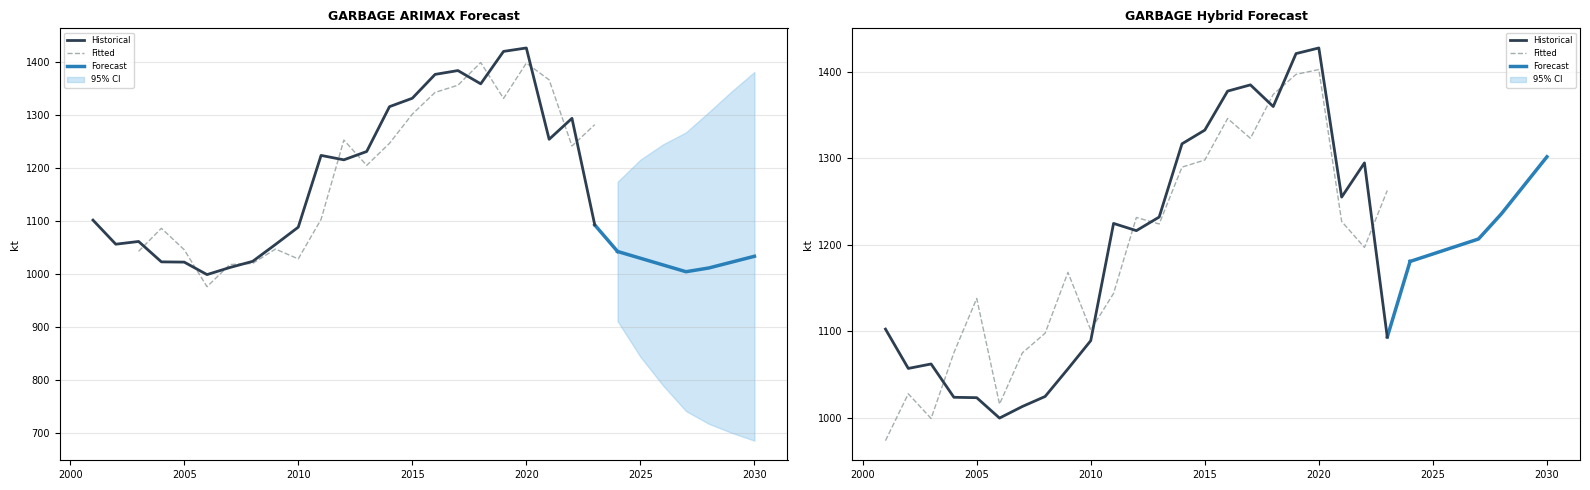

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

configs = [
    {"df": df_fc_garbage_arimax, "ax": axes[0], "label": "GARBAGE ARIMAX Forecast"},
    {"df": df_fc_garbage_hybrid, "ax": axes[1], "label": "GARBAGE Hybrid Forecast"}
]

for cfg in configs:
    plot_series(
        ax=cfg["ax"],
        fc_df=cfg["df"],
        ylabel="kt",  
        title=cfg["label"]
    )

plt.tight_layout()
plt.show()

#### Glass
Chosen Method: ARIMAX  
Not-reliable due to limited historical data

In [25]:
glass_series = annual_df["glass_collected"].dropna()
valid_idx = glass_series.index

exog_hist = pd.DataFrame({
    "glass_adoption": annual_df.loc[valid_idx, "councils_with_glass"],
    "population": annual_df.loc[valid_idx, "population"]
}, index=valid_idx)

exog_future = pd.DataFrame({
    "glass_adoption": glass_adoption_future,
    "population": population_future
}, index=years_future)

In [26]:
df_fc_glass_arima, metrics_glass_arima = fit_arima(
    series=annual_df["glass_collected"],
    label="GLASS",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)


df_fc_glass_arimax, metrics_glass_arimax = fit_arimax(
    series=glass_series,
    label="GLASS",
    forecast_steps=7,
    test_size=3,
    exog_hist=exog_hist,
    exog_future=exog_future
)


[GLASS] ARIMA
Best order: ARIMA(0, 0, 0)
    Test Set Evaluation:
    MAE  = 6.4067
    RMSE = 6.4067
    MAPE = 38.92%

[GLASS] ARIMAX
Best order: ARIMA(0, 0, 0)
    Test Set Evaluation:
    MAE  = 0.6994
    RMSE = 0.6994
    MAPE = 4.25%


#### Recycling
Tested:
1. ARIMA (Univariate)
1. ARIMAX, with `premises_with_recycling` as exog driver
2. Hybrid (Regression + ARIMAX), with `premises_with_recycling` as exog driver

Chosen method: ARIMAX

In [27]:
exog_future = pd.DataFrame({
    "recycling_service": recycling_service_future
}, index=years_future)

df_fc_recycling_arima, metrics_recycling_arima = fit_arima(
    series=annual_df["recycling_collected"],
    label="RECYCLING",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA,
    max_d = 1
)

df_fc_recycling_arimax, metrics_recycling_arimax = fit_arimax(
    series=annual_df["recycling_collected"],
    label="RECYCLING",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["premises_with_recycling"]].to_numpy(),
    exog_future=exog_future,
    ci_alpha=ALPHA,
    max_d = 1
)

df_fc_recycling_hybrid, metrics_recycling_hybrid = fit_linear_regression_arima(
    series=annual_df["recycling_collected"],
    label="RECYCLING",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["premises_with_recycling"]].to_numpy(),
    exog_future=exog_future,
)


[RECYCLING] ARIMA
Best order: ARIMA(1, 1, 0)
    Test Set Evaluation:
    MAE  = 104.3435
    RMSE = 107.8840
    MAPE = 19.39%

[RECYCLING] ARIMAX
Best order: ARIMA(1, 1, 0)
    Test Set Evaluation:
    MAE  = 78.7108
    RMSE = 84.8465
    MAPE = 14.68%

[RECYCLING] HYBRID (Linear Regression + Auto-ARIMA Residuals)
    train=20  test=3
    Best Residual Order: ARIMA(4, 0, 0)
    Test set evaluation:
    MAE  = 73.7375
    RMSE = 85.1067
    MAPE = 13.81%


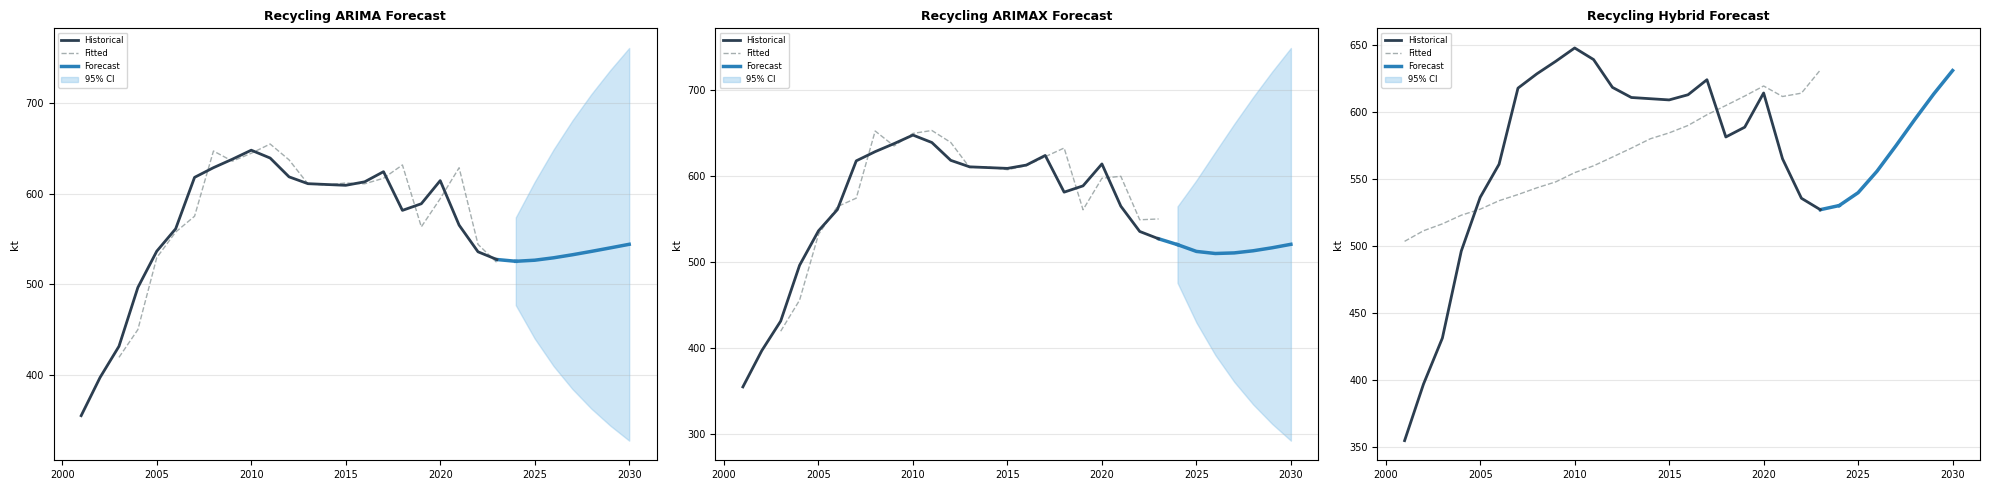

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

configs = [
    {"df": df_fc_recycling_arima, "ax": axes[0], "label": "Recycling ARIMA Forecast"},
    {"df": df_fc_recycling_arimax, "ax": axes[1], "label": "Recycling ARIMAX Forecast"},
    {"df": df_fc_recycling_hybrid, "ax": axes[2], "label": "Recycling Hybrid Forecast"}
]

for cfg in configs:
    plot_series(
        ax=cfg["ax"],
        fc_df=cfg["df"],
        ylabel="kt",  
        title=cfg["label"]
    )

plt.tight_layout()
plt.show()

#### FOGO
Tested:
1. ARIMAX, with `fogo_adoption_rate` as exog driver
2. Hybrid (Regression + ARIMAX), with `fogo_adoption_rate` as exog driver

Chosen method: ARIMAX

In [73]:
df_fc_fogo_arima, metrics_fogo_arima = fit_arima(
    series=annual_df["fogo_collected"],
    label="FOGO",
    forecast_steps=7,
    test_size=3,
)

exog_future = pd.DataFrame({
    "fogo_adoption": fogo_adoption_future,
    "population": population_future
}, index=years_future)

df_fc_fogo_arimax, metrics_fogo_arimax = fit_arimax(
    series=annual_df["fogo_collected"],
    label="FOGO",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["councils_with_fogo", "population"]].to_numpy(),
    exog_future=exog_future
)

df_fc_fogo_hybrid, metrics_fogo_hybrid = fit_linear_regression_arima(
    series=annual_df["fogo_collected"],
    label="FOGO",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["councils_with_fogo", "population"]].to_numpy(),
    exog_future=exog_future,
)


[FOGO] ARIMA
Best order: ARIMA(1, 1, 0)
    Test Set Evaluation:
    MAE  = 208.8438
    RMSE = 221.3355
    MAPE = 38.18%

[FOGO] ARIMAX
Best order: ARIMA(1, 1, 0)
    Test Set Evaluation:
    MAE  = 22.8123
    RMSE = 26.7634
    MAPE = 4.56%

[FOGO] HYBRID (Linear Regression + Auto-ARIMA Residuals)
    train=20  test=3
    Best Residual Order: ARIMA(1, 0, 0)
    Test set evaluation:
    MAE  = 39.3806
    RMSE = 46.4310
    MAPE = 6.88%


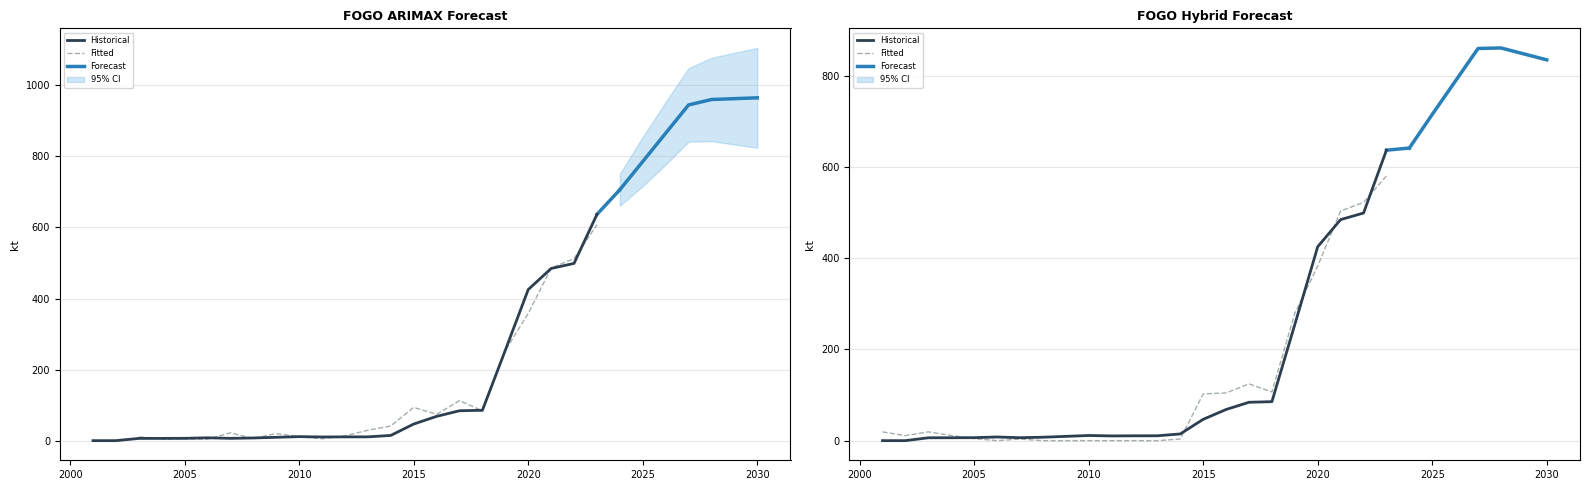

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

configs = [
    {"df": df_fc_fogo_arimax, "ax": axes[0], "label": "FOGO ARIMAX Forecast"},
    {"df": df_fc_fogo_hybrid, "ax": axes[1], "label": "FOGO Hybrid Forecast"}
]

for cfg in configs:
    plot_series(
        ax=cfg["ax"],
        fc_df=cfg["df"],
        ylabel="kt",  
        title=cfg["label"]
    )

plt.tight_layout()
plt.show()

#### GO
Tested
1. ARIMA 
2. ETS 
 
Chosen Method: ETS

In [75]:
df_fc_go_ets, metrics_go_ets = fit_ets(
    series=annual_df["go_collected"],
    label="GO",
    forecast_steps=7,
    test_size=3
)

df_fc_go_arima, metrics_go_arima = fit_arima(
    series=annual_df["go_collected"],
    label="GO",
    forecast_steps=7,
    test_size=3,
)

exog_future = pd.DataFrame({
    "fogo_adoption": fogo_adoption_future,
    "population": population_future
}, index=years_future)

df_fc_go_arimax, metrics_go_arimax = fit_arimax(
    series=annual_df["go_collected"],
    label="GO",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["councils_with_fogo", "population"]].to_numpy(),
    exog_future=exog_future
)


  [GO] [ETS damped]
    train=20  test=3  horizon=7  reliability=high (n=23)
    Test set evaluation:
    MAE  = 27.3639
    RMSE = 29.4449
    MAPE = 24.42%
    AIC=152.68  (CV not applicable for ETS)

[GO] ARIMA
Best order: ARIMA(0, 2, 0)
    Test Set Evaluation:
    MAE  = 138.0996
    RMSE = 161.9722
    MAPE = 135.43%

[GO] ARIMAX
Best order: ARIMA(0, 2, 0)
    Test Set Evaluation:
    MAE  = 140.8411
    RMSE = 158.4128
    MAPE = 135.33%


#### Hard Waste
Tested:
1. ARIMA (Univariate)
2. ARIMAX, with population as exog driver.
  
Chosen method: ARIMA

In [32]:
df_fc_hardwaste_arima, metrics_hardwaste_arima = fit_arima(
    series=annual_df["hardwaste_collected"],
    label="HARDWASTE",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

exog_future = pd.DataFrame({
    "population": population_future
}, index=years_future)

df_fc_hardwaste_arimax, metrics_hardwaste_arimax = fit_arimax(
    series=annual_df["hardwaste_collected"],
    label="HARDWASTE",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["population"]].to_numpy(),
    exog_future=exog_future
)


[HARDWASTE] ARIMA
Best order: ARIMA(0, 1, 1)
    Test Set Evaluation:
    MAE  = 7.4311
    RMSE = 7.6635
    MAPE = 6.34%

[HARDWASTE] ARIMAX
Best order: ARIMA(0, 1, 1)
    Test Set Evaluation:
    MAE  = 15.8334
    RMSE = 15.9785
    MAPE = 13.44%


#### Actual Recycled

Chosen Method: ARIMA

In [33]:
df_fc_recycled_arima, metrics_recycled_arima = fit_arima(
    series=annual_df["recycling_actual_recycled"],
    label="RECYCLING ACTUAL RECYCLED",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

df_fc_recycled_ets, metrics_recycled_ets = fit_ets(
    series=annual_df["recycling_actual_recycled"],
    label="RECYCLING ACTUAL RECYCLED",
    forecast_steps=7,
    test_size=3
)

recycling_collected_future = df_fc_recycling_arimax[df_fc_recycling_arimax["index"]>2023]["fitted"].to_numpy()

exog_future = pd.DataFrame({
    "recycling_collected": recycling_collected_future
}, index=years_future)


df_fc_recycled_arimax, metrics_recycled_arimax = fit_arimax(
    series=annual_df["recycling_actual_recycled"],
    label="RECYCLING ACTUAL RECYCLED",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["recycling_collected"]].to_numpy(),
    exog_future=exog_future,
)


[RECYCLING ACTUAL RECYCLED] ARIMA
Best order: ARIMA(2, 0, 0)
    Test Set Evaluation:
    MAE  = 90.6183
    RMSE = 92.3902
    MAPE = 21.36%

  [RECYCLING ACTUAL RECYCLED] [ETS damped]
    train=20  test=3  horizon=7  reliability=high (n=23)
    Test set evaluation:
    MAE  = 77.5889
    RMSE = 78.8042
    MAPE = 18.28%
    AIC=108.90  (CV not applicable for ETS)

[RECYCLING ACTUAL RECYCLED] ARIMAX
Best order: ARIMA(2, 0, 0)
    Test Set Evaluation:
    MAE  = 56.6098
    RMSE = 57.3954
    MAPE = 13.33%


#### Processed Organics

Chosen Method: ARIMA

In [34]:
df_fc_organics_processed_arima, metrics_organics_processed_arima = fit_arima(
    series=annual_df["organics_processed"],
    label="ORGANICS PROCESSED",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

df_fc_organics_ets, metrics_organics_ets = fit_ets(
    series=annual_df["organics_processed"],
    label="ORGANICS PROCESSED",
    forecast_steps=7,
    test_size=3
)

fogo_collected_future = df_fc_fogo_arimax[df_fc_fogo_arimax["index"]>2023]["fitted"].to_numpy()
go_collected_future = df_fc_go_ets[df_fc_go_ets["index"]>2023]["fitted"].to_numpy()
organics_collected_future = fogo_collected_future + go_collected_future

exog_future = pd.DataFrame({
    "organics_collected": organics_collected_future
}, index=years_future)


df_fc_organics_processed_arimax, metrics_organics_processed_arimax = fit_arimax(
    series=annual_df["organics_processed"],
    label="ORGANICS PROCESSED",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[["organics_collected"]].to_numpy(),
    exog_future=exog_future,
)


[ORGANICS PROCESSED] ARIMA
Best order: ARIMA(0, 1, 0)
    Test Set Evaluation:
    MAE  = 47.1830
    RMSE = 52.2975
    MAPE = 7.67%

  [ORGANICS PROCESSED] [ETS damped]
    train=20  test=3  horizon=7  reliability=high (n=23)
    Test set evaluation:
    MAE  = 53.5775
    RMSE = 60.3787
    MAPE = 8.14%
    AIC=152.08  (CV not applicable for ETS)

[ORGANICS PROCESSED] ARIMAX
Best order: ARIMA(0, 1, 0)
    Test Set Evaluation:
    MAE  = 17.9678
    RMSE = 17.9953
    MAPE = 2.82%


#### Total Waste Generation (MSW)

Derived from related components.

In [35]:
total_waste_all_fc_dict = {
    "garbage": df_fc_garbage_arimax,
    "recycling": df_fc_recycling_arimax,
    "glass": df_fc_glass_arimax,
    "fogo": df_fc_fogo_arimax,
    "go": df_fc_go_ets,
    "hardwaste": df_fc_hardwaste_arima,
}

total_waste_components = ["garbage", "recycling", "glass", "fogo", "go", "hardwaste"]

df_total_waste_msw = derive_total_from_components(
    all_fc_dict=total_waste_all_fc_dict,
    component_cols=total_waste_components,
    label="Total Waste Generation (MSW)"
)

#### Waste Per Capita
Derived from related components.

In [36]:
population_df = annual_df[["population"]].copy()

population_future_df = pd.DataFrame(
    population_future,
    index=years_future,
    columns=["population"]
)

population_df = pd.concat([population_df, population_future_df])
population_df = population_df.reset_index().rename(columns={"index": "year"})

df_waste_per_capita_municipal = pd.DataFrame({
    "index": df_total_waste_msw["index"],
    "actual": (
        df_total_waste_msw["actual"] / population_df["population"]) * 1000000,
    "fitted": (
        df_total_waste_msw["fitted"] / population_df["population"]) * 1000000,
    "lower_ci": (
        df_total_waste_msw["lower_ci"] / population_df["population"]) * 1000000,
    "upper_ci": (
        df_total_waste_msw["upper_ci"] / population_df["population"]) * 1000000,
    "is_forecast": df_total_waste_msw["is_forecast"],
    "series": "Waste Per Capita (Municipal)",
    "reliability": "derived"
})

#### Total Waste Generation (Full)
Chosen Method: ARIMA

In [37]:
df_fc_total_waste_arima, metrics_total_waste_arima = fit_arima(
    series=annual_df["total_generation_full"],
    label="TOTAL WASTE GENERATION (Full)",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

exog_future = pd.DataFrame({
    "population": population_future,
}, index=years_future)

df_fc_total_waste_arimax, metrics_total_waste_arimax = fit_arimax(
    series=annual_df["total_generation_full"],
    label="TOTAL WASTE GENERATION (Full)",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[annual_df.index > 2014][["population"]].to_numpy(),
    exog_future=exog_future,
    ci_alpha=ALPHA,
)


[TOTAL WASTE GENERATION (Full)] ARIMA
Best order: ARIMA(1, 0, 0)
    Test Set Evaluation:
    MAE  = 3036.7294
    RMSE = 3132.1759
    MAPE = 21.16%

[TOTAL WASTE GENERATION (Full)] ARIMAX
Best order: ARIMA(1, 0, 0)
    Test Set Evaluation:
    MAE  = 1131.7502
    RMSE = 1285.9960
    MAPE = 7.90%


#### Disposal (Full)
Chosen Method: ARIMA

In [38]:
df_fc_disposal_arima, metrics_disposal_arima = fit_arima(
    series=annual_df["disposal_full"],
    label="DISPOSAL (Full)",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

exog_future = pd.DataFrame({
    "population": population_future,
}, index=years_future)

df_fc_disposal_arimax, metrics_disposal_arimax = fit_arimax(
    series=annual_df["disposal_full"],
    label="DISPOSAL (Full)",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[annual_df.index > 2014][["population"]].to_numpy(),
    exog_future=exog_future,
    ci_alpha=ALPHA,
)


[DISPOSAL (Full)] ARIMA
Best order: ARIMA(2, 0, 0)
    Test Set Evaluation:
    MAE  = 798.5264
    RMSE = 915.5085
    MAPE = 18.10%

[DISPOSAL (Full)] ARIMAX
Best order: ARIMA(2, 0, 0)
    Test Set Evaluation:
    MAE  = 209.4460
    RMSE = 294.7609
    MAPE = 4.79%


In [39]:
df_fc_disposal_arimax

,index,actual,fitted,lower_ci,upper_ci,is_forecast,series,reliability
0,2015,4138.78,NaN,NaN,NaN,False,DISPOSAL (Full),low
1,2016,4199.34,NaN,NaN,NaN,False,DISPOSAL (Full),low
2,2017,4392.82,4336.751320,4000.564141,4672.938499,False,DISPOSAL (Full),low
3,2018,4536.26,4529.389414,4193.202235,4865.576593,False,DISPOSAL (Full),low
4,2019,4763.98,4592.345474,4256.158295,4928.532653,False,DISPOSAL (Full),low
5,2020,4691.90,4689.803842,4353.616663,5025.991021,False,DISPOSAL (Full),low
6,2021,4525.00,4330.594545,3994.407366,4666.781724,False,DISPOSAL (Full),low
7,2022,4517.46,4488.825959,4152.638780,4825.013137,False,DISPOSAL (Full),low
8,2023,4335.41,4702.403217,4366.216038,5038.590396,False,DISPOSAL (Full),low
9,2024,NaN,4659.623920,4323.436741,4995.811099,True,DISPOSAL (Full),low


#### Diversion Rate
Derived from related components.

In [40]:
df_diversion = pd.DataFrame({
    "index": df_fc_total_waste_arima["index"],
    "actual": (
        (df_fc_total_waste_arima["actual"] - df_fc_disposal_arima["actual"])
        / df_fc_total_waste_arima["actual"]
    ) * 100,
    "fitted": (
        (df_fc_total_waste_arima["fitted"] - df_fc_disposal_arima["fitted"])
        / df_fc_total_waste_arima["fitted"]
    ) * 100,
    "lower_ci": (
        (df_fc_total_waste_arima["lower_ci"] - df_fc_disposal_arima["upper_ci"])
        / df_fc_total_waste_arima["upper_ci"]
    ) * 100,
    "upper_ci": (
        (df_fc_total_waste_arima["upper_ci"] - df_fc_disposal_arima["lower_ci"])
        / df_fc_total_waste_arima["lower_ci"]
    ) * 100,
    "is_forecast": df_fc_disposal_arima["is_forecast"],
    "series": "Diversion Rate",
    "reliability": "derived"
})

#### Waste Per Capita (Full)

In [41]:
population_df = annual_df[["population"]].copy()
population_df = population_df[population_df.index > 2014]

population_future_df = pd.DataFrame(
    population_future,
    index=years_future,
    columns=["population"]
)

population_df = pd.concat([population_df, population_future_df])
population_df = population_df.reset_index().rename(columns={"index": "year"})

df_waste_per_capita = pd.DataFrame({
    "index": df_fc_total_waste_arimax["index"],
    "actual": (
        df_fc_total_waste_arima["actual"] / population_df["population"]) * 1000000,
    "fitted": (
        df_fc_total_waste_arima["fitted"] / population_df["population"]) * 1000000,
    "lower_ci": (
        df_fc_total_waste_arima["lower_ci"] / population_df["population"]) * 1000000,
    "upper_ci": (
        df_fc_total_waste_arima["upper_ci"] / population_df["population"]) * 1000000,
    "is_forecast": df_fc_total_waste_arima["is_forecast"],
    "series": "Waste Per Capita (Full)",
    "reliability": "derived"
})

#### Total Organics Generation and Disposal

In [42]:
df_fc_total_organics_arima, metrics_total_organics_arima = fit_arima(
    series=annual_df["total_generation_organics"],
    label="TOTAL ORGANICS GENERATION (Full)",
    forecast_steps=7,
    test_size=3,
    ci_alpha=ALPHA
)

exog_future = pd.DataFrame({
    "fogo_adoption": fogo_adoption_future,
    "population": population_future
}, index=years_future)

df_fc_total_organics_arimax, metrics_total_organics_arimax = fit_arimax(
    series=annual_df["total_generation_organics"],
    label="TOTAL ORGANICS GENERATION (Full)",
    forecast_steps=7,
    test_size=3,
    exog_hist=annual_df[annual_df.index > 2014][["councils_with_fogo", "population"]].to_numpy(),
    exog_future=exog_future
)


[TOTAL ORGANICS GENERATION (Full)] ARIMA
Best order: ARIMA(1, 0, 0)
    Test Set Evaluation:
    MAE  = 826.8597
    RMSE = 849.4909
    MAPE = 27.16%

[TOTAL ORGANICS GENERATION (Full)] ARIMAX
Best order: ARIMA(1, 0, 0)
    Test Set Evaluation:
    MAE  = 421.8602
    RMSE = 442.7966
    MAPE = 13.86%


In [74]:
total_organics_future = df_fc_total_organics_arima[df_fc_total_organics_arima['index']>2023]['fitted'].to_numpy()

exog_future = pd.DataFrame({
    "fogo_adoption": fogo_adoption_future,
    "total_organics": total_organics_future,
}, index=years_future)

organics_disposal_series = annual_df["disposal_organics"].dropna()
valid_idx = organics_disposal_series.index

exog_hist = pd.DataFrame({
    "fogo_adoption": annual_df.loc[valid_idx, "councils_with_fogo"],
    "total_organics": annual_df.loc[valid_idx, "total_generation_organics"],
}, index=valid_idx)

df_fc_disposal_organics_arima, metrics_disposal_organics_arima = fit_arima(
    series=organics_disposal_series,
    label="DISPOSAL ORGANICS (FULL)",
    forecast_steps=7,
    test_size=3,
)

df_fc_disposal_organics_arimax, metrics_disposal_organics_arimax = fit_arimax(
    series=organics_disposal_series,
    label="DISPOSAL ORGANICS (FULL)",
    forecast_steps=7,
    test_size=3,
    exog_hist=exog_hist,
    exog_future=exog_future
)

df_fc_disposal_organics_hybrid, metrics_disposal_organics_hybrid = fit_linear_regression_arima(
    series=annual_df["disposal_organics"],
    label="DISPOSAL ORGANICS (FULL)",
    forecast_steps=7,
    test_size=3,
    exog_hist=exog_hist,
    exog_future=exog_future,
)


[DISPOSAL ORGANICS (FULL)] ARIMA
Best order: ARIMA(0, 0, 0)
    Test Set Evaluation:
    MAE  = 106.5379
    RMSE = 112.1583
    MAPE = 6.96%

[DISPOSAL ORGANICS (FULL)] ARIMAX
Best order: ARIMA(0, 0, 0)
    Test Set Evaluation:
    MAE  = 299.6626
    RMSE = 302.4597
    MAPE = 19.49%

[DISPOSAL ORGANICS (FULL)] HYBRID (Linear Regression + Auto-ARIMA Residuals)
    train=6  test=3
    Best Residual Order: ARIMA(0, 0, 0)
    Test set evaluation:
    MAE  = 694.8506
    RMSE = 708.9217
    MAPE = 45.26%


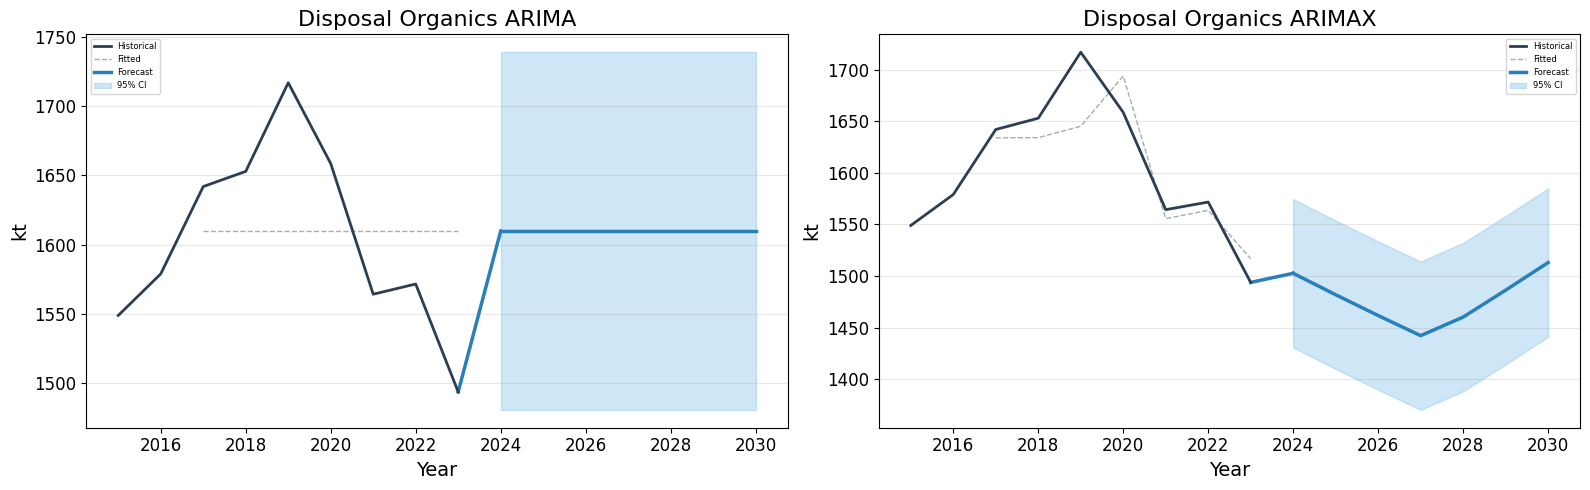

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

configs = [
    {"df": df_fc_disposal_organics_arima, "ax": axes[0], "label": "Disposal Organics ARIMA"},
    {"df": df_fc_disposal_organics_arimax, "ax": axes[1], "label": "Disposal Organics ARIMAX"}
]

for cfg in configs:
    plot_series(
        ax=cfg["ax"],
        fc_df=cfg["df"],
        ylabel="kt",  
        title=cfg["label"]
    )

    cfg["ax"].set_title(cfg["label"], fontsize=16)
    cfg["ax"].set_xlabel("Year", fontsize=14)   # if you have x-label
    cfg["ax"].set_ylabel("kt", fontsize=14)

    # increase tick label size
    cfg["ax"].tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

### Full Forecast Graph

In [44]:
glass_df = annual_df[["councils_with_glass"]].copy()
glass_df = glass_df.reset_index()
glass_df = glass_df.rename(columns={"start_year": "index", "councils_with_glass": "actual"})
glass_df["category"] = "Glass Adoption"
glass_df["is_forecast"] = False

glass_future_df = pd.DataFrame({
    "index": years_future,
    "fitted": glass_adoption_future.astype(int),
    "category": "Glass Adoption",
    "is_forecast": True,
    "lower_ci": np.nan,
    "upper_ci": np.nan,
    "reliabiliy": "Low"
})

glass_adoption_df = pd.concat([glass_df, glass_future_df], ignore_index=True)

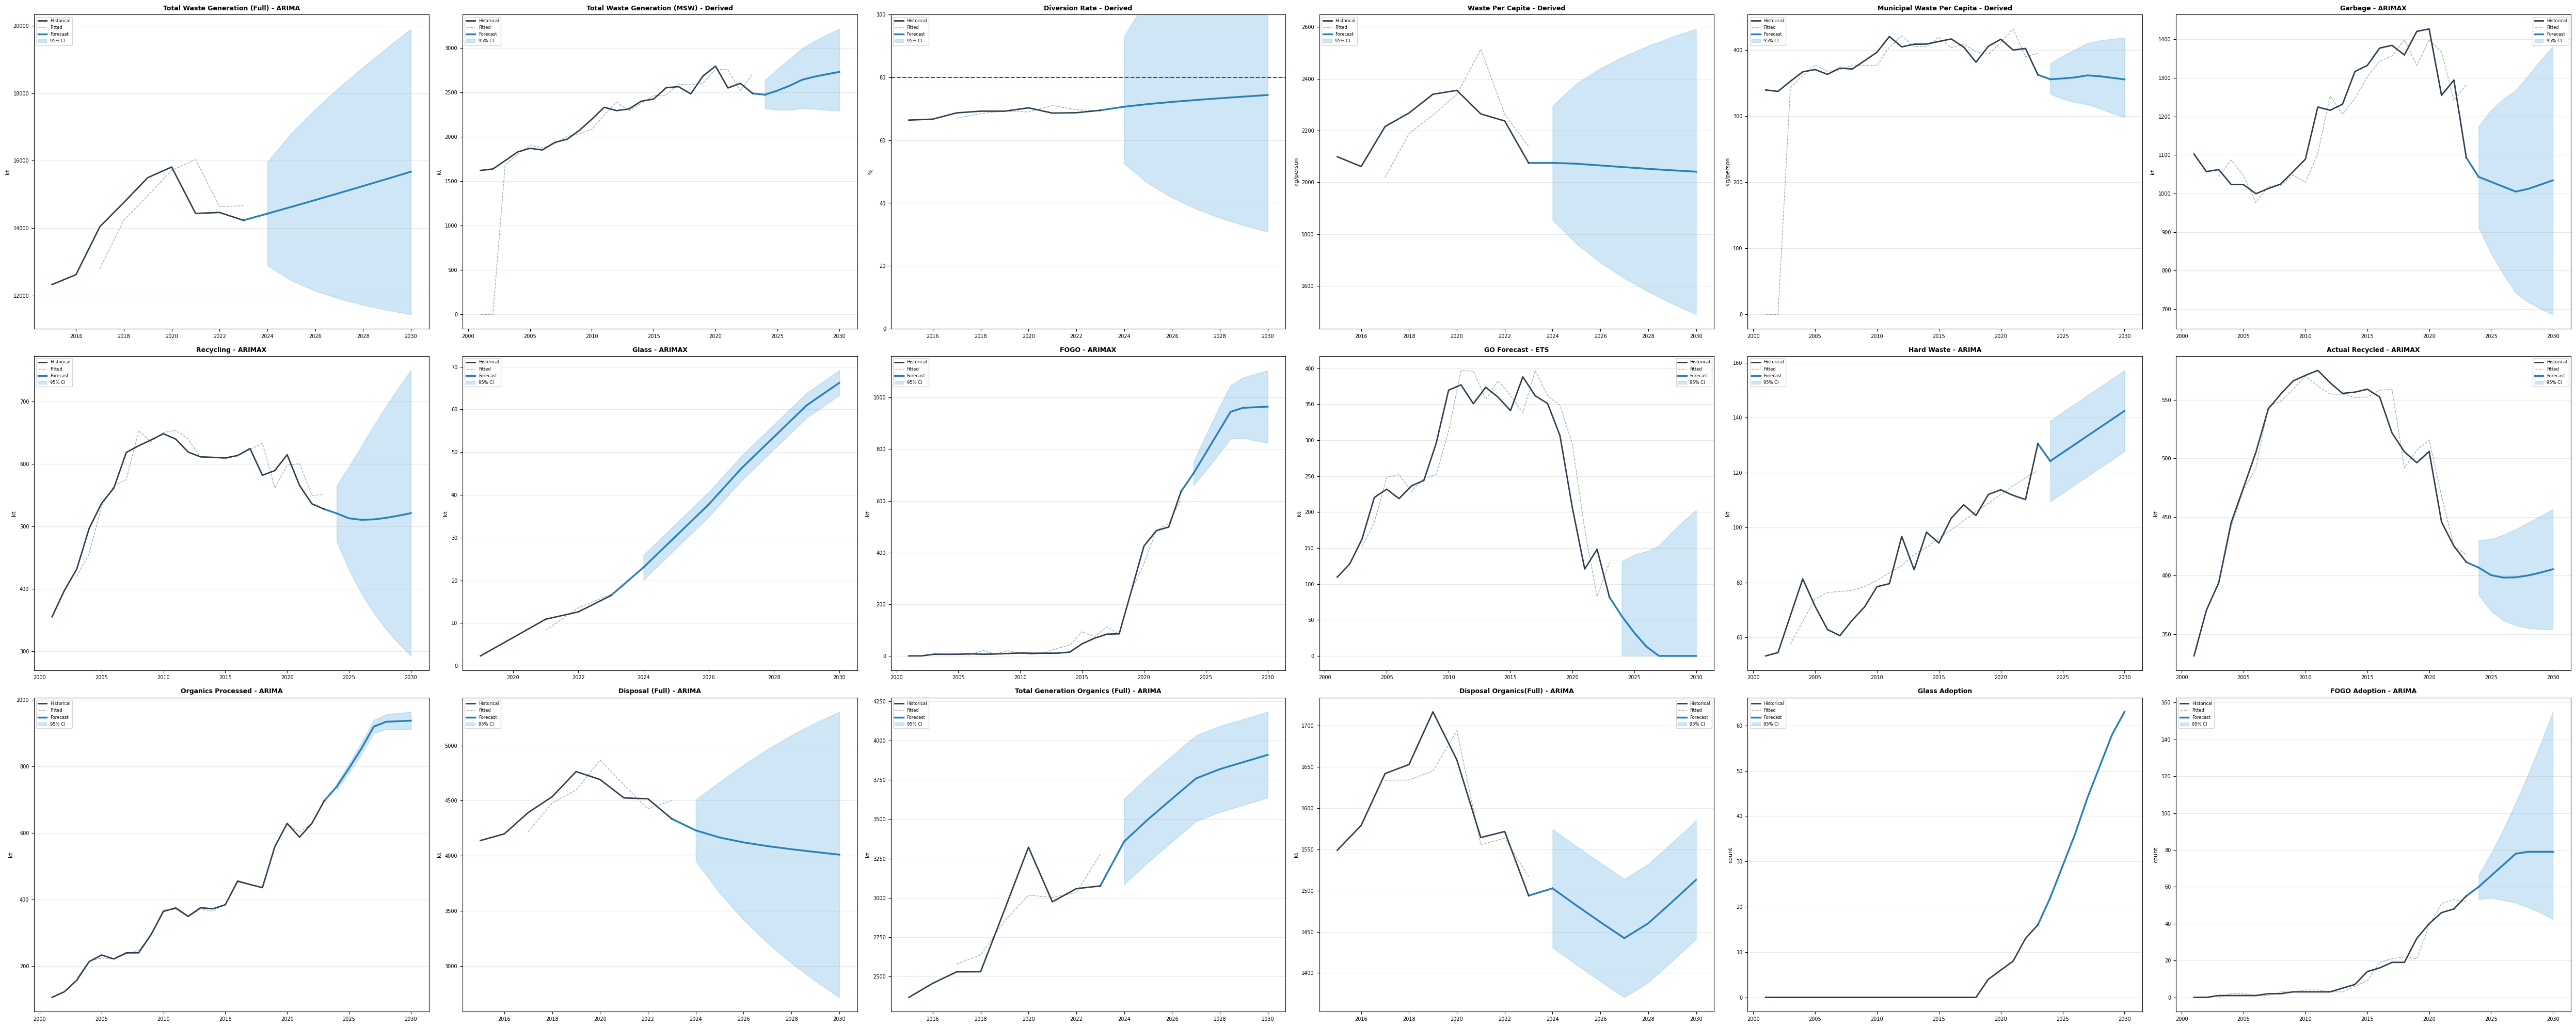

In [45]:
fig, axes = plt.subplots(3, 6, figsize=(50, 20))
axes_flat = axes.flatten()

configs = [
    {"df": df_fc_total_waste_arima, "ax": axes_flat[0], "label": "Total Waste Generation (Full) - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": df_total_waste_msw, "ax": axes_flat[1], "label": "Total Waste Generation (MSW) - Derived", "ylabel": "kt", "ylim": None},
    {"df": df_diversion, "ax": axes_flat[2], "label": "Diversion Rate - Derived", "ylabel": "%", "ylim": (0, 100)},
    {"df": df_waste_per_capita, "ax": axes_flat[3], "label": "Waste Per Capita - Derived", "ylabel": "kg/person", "ylim": None},
    {"df": df_waste_per_capita_municipal, "ax": axes_flat[4], "label": "Municipal Waste Per Capita - Derived", "ylabel": "kg/person", "ylim": None},
    {"df": df_fc_garbage_arimax, "ax": axes_flat[5], "label": "Garbage - ARIMAX", "ylabel": "kt", "ylim": None},
    {"df": df_fc_recycling_arimax, "ax": axes_flat[6], "label": "Recycling - ARIMAX", "ylabel": "kt", "ylim": None},
    {"df": df_fc_glass_arimax, "ax": axes_flat[7], "label": "Glass - ARIMAX", "ylabel": "kt", "ylim": None},
    {"df": df_fc_fogo_arimax,    "ax": axes_flat[8], "label": "FOGO - ARIMAX", "ylabel": "kt", "ylim": None},
    {"df": df_fc_go_ets, "ax": axes_flat[9], "label": "GO Forecast - ETS", "ylabel": "kt", "ylim": None},
    {"df": df_fc_hardwaste_arima, "ax": axes_flat[10], "label": "Hard Waste - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": df_fc_recycled_arimax, "ax": axes_flat[11], "label": "Actual Recycled - ARIMAX", "ylabel": "kt", "ylim": None},
    {"df": df_fc_organics_processed_arimax, "ax": axes_flat[12], "label": "Organics Processed - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": df_fc_disposal_arima, "ax": axes_flat[13], "label": "Disposal (Full) - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": df_fc_total_organics_arimax, "ax": axes_flat[14], "label": "Total Generation Organics (Full) - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": df_fc_disposal_organics_arimax, "ax": axes_flat[15], "label": "Disposal Organics(Full) - ARIMA", "ylabel": "kt", "ylim": None},
    {"df": glass_adoption_df, "ax": axes_flat[16], "label": "Glass Adoption", "ylabel": "count", "ylim": None},
    {"df": df_fc_fogo_adoption_rate, "ax": axes_flat[17], "label": "FOGO Adoption - ARIMA", "ylabel": "count", "ylim": None}

]
    
for cfg in configs:
    plot_series(
        ax=cfg["ax"],
        fc_df=cfg["df"],
        ylabel=cfg["ylabel"],  
        title=cfg["label"],
        ylim=cfg["ylim"]
    )

    if cfg["label"] == "Diversion Rate - Derived" or cfg["label"] == "Kerbside Diversion Rate - Derived":
        cfg["ax"].axhline(
            y=80,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label="Target (80%)"
        )

plt.tight_layout()
plt.show()

### Model Evaluation Summary

In [46]:
all_metrics = [metrics_total_waste_arima, metrics_disposal_arima, metrics_garbage_arimax, metrics_recycling_arimax,
               metrics_glass_arimax, metrics_fogo_arimax, metrics_go_ets,
               metrics_hardwaste_arima, metrics_recycled_arimax, metrics_organics_processed_arimax, 
               metrics_total_organics_arimax, metrics_disposal_organics_arimax, metrics_fogo_adoption_rate]

eval_df = pd.DataFrame(all_metrics)
eval_df

,series,MAE,RMSE,MAPE_pct,order,AIC,test_size,n_years_history,ci_alpha_used,cv_mae_mean,cv_rmse_mean,cv_mape_mean,cv_folds,reliability,model
0,TOTAL WASTE GENERATION (Full),3036.7294,3132.1759,21.16,"(1, 0, 0)",104.46,3,9,0.05,NaN,NaN,NaN,0,low,ARIMA
1,DISPOSAL (Full),798.5264,915.5085,18.10,"(2, 0, 0)",82.96,3,9,0.05,NaN,NaN,NaN,0,low,ARIMA
2,GARBAGE,216.7282,244.2928,18.64,"(0, 1, 0)",199.96,3,23,0.05,30.9000,30.9000,2.20,3,high,ARIMAX
3,RECYCLING,78.7108,84.8465,14.68,"(1, 1, 0)",177.54,3,23,0.05,36.2076,36.2076,6.13,3,high,ARIMAX
4,GLASS,0.6994,0.6994,4.25,"(0, 0, 0)",26.44,3,5,0.05,NaN,NaN,NaN,0,low,ARIMAX
5,FOGO,22.8123,26.7634,4.56,"(1, 1, 0)",200.03,3,23,0.05,72.6338,72.6338,29.19,3,high,ARIMAX
6,GO,27.3639,29.4449,24.42,ETS(AAdm),152.68,3,23,NaN,NaN,NaN,NaN,0,high,ETS
7,HARDWASTE,7.4311,7.6635,6.34,"(0, 1, 1)",137.68,3,23,0.05,4.3771,4.3771,3.96,3,high,ARIMA
8,RECYCLING ACTUAL RECYCLED,56.6098,57.3954,13.33,"(2, 0, 0)",173.94,3,23,0.05,11.6823,11.6823,2.32,3,high,ARIMAX
9,ORGANICS PROCESSED,17.9678,17.9953,2.82,"(0, 1, 0)",194.94,3,23,0.05,67.3633,67.3633,11.74,3,high,ARIMAX


### Export Forecast Data

In [80]:
forecast_dfs = {
    "Total Waste Generation (Full)": df_fc_total_waste_arima,
    "Total Waste Generation (MSW)": df_total_waste_msw,
    "Diversion Rate": df_diversion,
    "Waste Per Capita (Full)": df_waste_per_capita,
    "Waste Per Capita (Municipal)": df_waste_per_capita_municipal,
    "Disposal (Full)": df_fc_disposal_arima,
    "Garbage": df_fc_garbage_hybrid,
    "Recycling": df_fc_recycling_arimax,
    "Glass": df_fc_glass_arimax,
    "FOGO": df_fc_fogo_arimax,
    "GO": df_fc_go_ets,
    "Hard Waste": df_fc_hardwaste_arima,
    "Actual Recycled": df_fc_recycled_arimax,
    "Organics Processed": df_fc_organics_processed_arima,
    "Total Organics Generation": df_fc_total_organics_arima,
    "Disposal Organics": df_fc_disposal_organics_arimax,
    "FOGO Adoption": df_fc_fogo_adoption_rate,
}

merged_forecasts = []

for category, df in forecast_dfs.items():

    hist_df = df[~df["is_forecast"]].copy()
    fc_df = df[df["is_forecast"]].copy()

    hist_cols = ["index", "actual", "fitted", "is_forecast", "reliability"]
    future_cols = ["index", "actual", "fitted", "lower_ci", "upper_ci", "is_forecast", "reliability"]

    hist_df = hist_df[hist_cols]
    if category in ["Diversion Rate", "Kerbside Diversion Rate"]:
        hist_df["value"] = hist_df["actual"] / 100
        hist_df["unit"] = "%"
    elif category in ["Waste Per Capita (Full)", "Waste Per Capita (Municipal)"]:
        hist_df["value"] = hist_df["actual"]
        hist_df["unit"] = "kg/person"
    elif category in ["FOGO Adoption"]:
        hist_df["value"] = hist_df["actual"]
        hist_df["unit"] = "Count"
    else:
        hist_df["value"] = hist_df["actual"] * 1000
        hist_df["unit"] = "tonnes"

    fc_df = fc_df[future_cols]
    if category in ["Diversion Rate", "Kerbside Diversion Rate"]:
        fc_df["value"] = fc_df["fitted"] / 100
        fc_df["lower_ci"] = fc_df["lower_ci"] / 100
        fc_df["upper_ci"] = fc_df["upper_ci"] / 100
        fc_df["unit"] = "%"
    elif category in ["Waste Per Capita (Full)", "Waste Per Capita (Municipal)"]:
        fc_df["value"] = fc_df["fitted"]
        fc_df["lower_ci"] = fc_df["lower_ci"]
        fc_df["upper_ci"] = fc_df["upper_ci"]
        fc_df["unit"] = "kg/person"
    elif category in ["FOGO Adoption"]:
        fc_df["value"] = fc_df["fitted"]
        fc_df["lower_ci"] = fc_df["lower_ci"]
        fc_df["upper_ci"] = fc_df["upper_ci"]
        fc_df["unit"] = "Count"
    else:
        fc_df["value"] = fc_df["fitted"] * 1000
        fc_df["lower_ci"] = fc_df["lower_ci"] * 1000
        fc_df["upper_ci"] = fc_df["upper_ci"] * 1000
        fc_df["unit"] = "tonnes"
    full_df = pd.concat([hist_df, fc_df], ignore_index=True)
    full_df = full_df.drop(columns=["actual", "fitted"])
    full_df["category"] = category

    merged_forecasts.append(full_df)

forecast_waste_all_df = pd.concat(
    merged_forecasts,
    ignore_index=True
)

forecast_waste_all_df = forecast_waste_all_df.rename(columns={"index": "year"})


## Scenario Modeling: Diversion Rate
### Diversion Rate

In [81]:
historical_total_generation = df_fc_total_waste_arima[['index', 'actual']].dropna()
historical_organics_genration = df_fc_total_organics_arima[['index', 'actual']].dropna()
historical_total_disposal = df_fc_disposal_arima[['index', 'actual']].dropna()
historical_organics_disposal = df_fc_disposal_organics_arimax[['index', 'actual']].dropna()

forecast_total_generation = df_fc_total_waste_arima[df_fc_total_waste_arima['index'] > 2023][['index', 'fitted']]
forecast_organics_genration = df_fc_total_organics_arima[df_fc_total_organics_arima['index'] > 2023][['index', 'fitted']]
forecast_total_disposal = df_fc_disposal_arima[df_fc_disposal_arima['index'] > 2023][['index', 'fitted']]
forecast_organics_disposal = df_fc_disposal_organics_arimax[df_fc_disposal_organics_arimax['index'] > 2023][['index', 'fitted']]

historical_total_generation = historical_total_generation.rename(
    columns={'actual': 'total_generation'}
)

forecast_total_generation = forecast_total_generation.rename(
    columns={'fitted': 'total_generation'}
)

historical_organics_generation = historical_organics_genration.rename(
    columns={'actual': 'organics_generation'}
)

forecast_organics_generation = forecast_organics_genration.rename(
    columns={'fitted': 'organics_generation'}
)

historical_total_disposal = historical_total_disposal.rename(
    columns={'actual': 'total_disposal'}
)

forecast_total_disposal = forecast_total_disposal.rename(
    columns={'fitted': 'total_disposal'}
)

historical_organics_disposal = historical_organics_disposal.rename(
    columns={'actual': 'organics_disposal'}
)

forecast_organics_disposal = forecast_organics_disposal.rename(
    columns={'fitted': 'organics_disposal'}
)

total_generation = pd.concat([
    historical_total_generation.assign(type='Historical'),
    forecast_total_generation.assign(type='Forecast')
])

organics_generation = pd.concat([
    historical_organics_generation.assign(type='Historical'),
    forecast_organics_generation.assign(type='Forecast')
])

total_disposal = pd.concat([
    historical_total_disposal.assign(type='Historical'),
    forecast_total_disposal.assign(type='Forecast')
])

organics_disposal = pd.concat([
    historical_organics_disposal.assign(type='Historical'),
    forecast_organics_disposal.assign(type='Forecast')
])

system_df = (
    total_generation
    .merge(total_disposal, on=['index', 'type'])
    .merge(organics_generation, on=['index', 'type'])
    .merge(organics_disposal, on=['index', 'type'])
)

In [82]:
system_df['recovered'] = (
    system_df['total_generation']
    - system_df['total_disposal']
)

system_df['diversion_rate'] = (
    system_df['recovered']
    / system_df['total_generation']
)

system_df['organics_diversion'] = (
    1 - (
        system_df['organics_disposal']
        / system_df['organics_generation']
    )
)

In [83]:
def apply_scenario(
    df,
    organics_disposal_change=0,
    total_generation_change=0
):
    out = df.copy()
    future_mask = out['type'] == 'Forecast'

    # 1. Apply generation change first (Scale both total and organics proportionally)
    out.loc[future_mask, 'total_generation'] *= (1 + total_generation_change)
    out.loc[future_mask, 'organics_generation'] *= (1 + total_generation_change)
    
    # Recompute non-organics generation just to keep the baseline clean
    out['non_org_generation'] = out['total_generation'] - out['organics_generation']

    # 2. Separate non-organic disposal BEFORE altering organics
    out['non_org_disposal'] = out['total_disposal'] - out['organics_disposal']

    # 3. Apply organics disposal scenario change
    out.loc[future_mask, 'organics_disposal'] *= (1 + organics_disposal_change)

    # 4. Recompute downstream metrics sequentially
    out['total_disposal'] = out['organics_disposal'] + out['non_org_disposal']
    out['recovered'] = out['total_generation'] - out['total_disposal']
    
    # Avoid zero-division errors just in case
    out['diversion_rate'] = out['recovered'] / out['total_generation'].replace(0, np.nan)
    out['organics_diversion'] = 1 - (out['organics_disposal'] / out['organics_generation'].replace(0, np.nan))

    return out

In [84]:
baseline = apply_scenario(system_df)

optimistic = apply_scenario(
    system_df,
    organics_disposal_change=-0.3,
    total_generation_change=-0.03
)

pessimistic = apply_scenario(
    system_df,
    organics_disposal_change=0.2,
    total_generation_change=0.02
)

baseline['scenario'] = 'Baseline'
optimistic['scenario'] = 'Optimistic'
pessimistic['scenario'] = 'Pessimistic'

scenario_df = pd.concat([
    baseline,
    optimistic,
    pessimistic
])

In [85]:
scenario_df[['index', 'type', 'scenario', 'diversion_rate']]

,index,type,scenario,diversion_rate
0,2015,Historical,Baseline,0.664204
1,2016,Historical,Baseline,0.667226
2,2017,Historical,Baseline,0.687187
3,2018,Historical,Baseline,0.692624
4,2019,Historical,Baseline,0.692528
5,2020,Historical,Baseline,0.703240
6,2021,Historical,Baseline,0.686521
7,2022,Historical,Baseline,0.687658
8,2023,Historical,Baseline,0.695340
9,2024,Forecast,Baseline,0.706767


In [86]:
optimistic = optimistic[['index', 'type', 'diversion_rate']].rename(columns={'index':'year', 'type': 'is_forecast', 'diversion_rate': 'value'})
pessimistic = pessimistic[['index', 'type', 'diversion_rate']].rename(columns={'index':'year', 'type': 'is_forecast', 'diversion_rate': 'value'})

optimistic['is_forecast'] = optimistic['is_forecast'].eq("is_forecast")
optimistic['category'] = "Diversion Rate Optimistic"
optimistic['unit'] = "%"
optimistic['reliability'] = "low"

pessimistic['is_forecast'] = pessimistic['is_forecast'].eq("is_forecast")
pessimistic['category'] = "Diversion Rate Pessimistic"
pessimistic['unit'] = "%"
pessimistic['reliability'] = "low"

### Glass Adoption

In [87]:
pessimistic_modifier = -0.20
optimistic_modifier = 0.3

glass_future_pes = np.round(glass_adoption_future * (1 + pessimistic_modifier), 0)
glass_future_op = np.round(np.clip(glass_adoption_future * (1 + optimistic_modifier), 0, 79.0), 0)

glass_future_op

array([29., 38., 47., 57., 66., 75., 79.])

In [88]:
# concat glass adoption forecast to forecast df
# baseline adoption
glass_df = annual_df[["councils_with_glass"]].copy()
glass_df = glass_df.reset_index()
glass_df = glass_df.rename(columns={"start_year": "year", "councils_with_glass": "value"})
glass_df["category"] = "Glass Adoption"
glass_df["is_forecast"] = False
glass_df["reliability"] = "low"

glass_future_df = pd.DataFrame({
    "year": years_future,
    "value": glass_adoption_future.astype(int),
    "category": "Glass Adoption",
    "is_forecast": True,
    "reliability": "low"
})

# optimistic adoption
glass_opt_df = glass_df.copy()
glass_opt_df["category"] = "Glass Adoption Optimistic"
glass_opt_future_df = pd.DataFrame({
    "year": years_future,
    "value": glass_future_op.astype(int),
    "category": "Glass Adoption Optimistic",
    "is_forecast": True,
    "reliability": "low"
})

glass_pes_df = glass_df.copy()
glass_pes_df["category"] = "Glass Adoption Pessimistic"
glass_pes_future_df = pd.DataFrame({
    "year": years_future,
    "value": glass_future_pes.astype(int),
    "category": "Glass Adoption Pessimistic",
    "is_forecast": True,
    "reliability": "low"
})

forecast_waste_all_df = pd.concat([forecast_waste_all_df, glass_df, glass_future_df, glass_opt_df, glass_opt_future_df, glass_pes_df, glass_pes_future_df], ignore_index=True)

In [89]:
forecast_waste_all_df = pd.concat([forecast_waste_all_df, optimistic, pessimistic], ignore_index=True)

In [90]:
forecast_waste_all_df.to_csv("Dataset/Semantic Model/fact_forecast_annual_waste.csv", index=False)

## Council Level Forecast: Diversion Rate

In [58]:
annual_lga_df = pd.read_csv("Dataset/ML/annual_by_lga.csv")
annual_lga_df = annual_lga_df.sort_values(["council", "start_year"])
annual_lga_df

,council,start_year,kerbside_total_waste,kerbside_diverted_waste,kerbside_diversion_rate
0,Alpine Shire Council,2001,3027.50,683.0000,0.225599
1,Alpine Shire Council,2002,3336.00,730.0000,0.218825
2,Alpine Shire Council,2003,2834.00,710.0000,0.250529
3,Alpine Shire Council,2004,3147.00,1097.5000,0.348745
4,Alpine Shire Council,2005,3361.78,1008.5000,0.299990
...,...,...,...,...,...
1808,Yarriambiack Shire Council,2019,2733.00,434.0000,0.158800
1809,Yarriambiack Shire Council,2020,2641.00,438.4000,0.165998
1810,Yarriambiack Shire Council,2021,2527.00,442.8000,0.175228
1811,Yarriambiack Shire Council,2022,2212.73,328.2190,0.148332


In [59]:
lga_forecast_results = []

for council, group in annual_lga_df.groupby("council"):

    group = group.dropna(subset=["kerbside_diversion_rate"])

    group = group.set_index("start_year")

    df, metrics = fit_arima(
        series=group["kerbside_diversion_rate"],
        label=f"KERBSIDE DIVERSION RATE",
        forecast_steps=7,
        test_size=3,
        ci_alpha=ALPHA,
        max_d = 1,
        print_eval=False
    )


    df["council"] = council

    lga_forecast_results.append(df)

In [60]:
lga_forecast_df = pd.concat(lga_forecast_results, ignore_index=True)
lga_forecast_df = lga_forecast_df.rename(columns={"index": "year"})
lga_forecast_df["value"] = np.where(
    lga_forecast_df["is_forecast"],
    lga_forecast_df["fitted"],
    lga_forecast_df["actual"]
)

lga_forecast_df["lower_ci"] = np.where(
    lga_forecast_df["is_forecast"],
    lga_forecast_df["lower_ci"],
    np.nan
)

lga_forecast_df["upper_ci"] = np.where(
    lga_forecast_df["is_forecast"],
    lga_forecast_df["upper_ci"],
    np.nan
)

lga_forecast_df["category"] = "Kerbside Diversion Rate"
lga_forecast_df = lga_forecast_df.drop(columns=["actual", "fitted", "series"])
lga_forecast_df

,year,lower_ci,upper_ci,is_forecast,reliability,council,value,category
0,2001,NaN,NaN,False,high,Alpine Shire Council,0.225599,Kerbside Diversion Rate
1,2002,NaN,NaN,False,high,Alpine Shire Council,0.218825,Kerbside Diversion Rate
2,2003,NaN,NaN,False,high,Alpine Shire Council,0.250529,Kerbside Diversion Rate
3,2004,NaN,NaN,False,high,Alpine Shire Council,0.348745,Kerbside Diversion Rate
4,2005,NaN,NaN,False,high,Alpine Shire Council,0.299990,Kerbside Diversion Rate
...,...,...,...,...,...,...,...,...
2361,2026,-0.033678,0.302742,True,high,Yarriambiack Shire Council,0.134532,Kerbside Diversion Rate
2362,2027,-0.070108,0.330040,True,high,Yarriambiack Shire Council,0.129966,Kerbside Diversion Rate
2363,2028,-0.100943,0.351983,True,high,Yarriambiack Shire Council,0.125520,Kerbside Diversion Rate
2364,2029,-0.127583,0.370007,True,high,Yarriambiack Shire Council,0.121212,Kerbside Diversion Rate


In [79]:
lga_forecast_df.to_csv("Dataset/Semantic Model/fact_forecast_annual_council_waste.csv", index=False)